# 03 — Diagnostics: where does the mock's photo-z error come from?

* **Noiseless vs noisy mock** (same 40k galaxies): the noiseless run isolates the *template-mismatch floor*. This is the error from fitting COSMOS templates to kcorrect SEDs with perfect photometry.
* **Zero-point offsets**: AUTO_ADAPT on the mock measures the systematic mismatch between the mock SED library and the COSMOS templates, band by band. Compared with the data offsets, which also absorb real calibration errors. The `sim_adapt` run applies the mock-derived offsets.
* **Fit quality**: χ²/N_band and best-fit template / E(B−V) distributions, data vs mock.
* **SOM**: a 20×20 SOM trained on the data's broad-band colours (u…Ks). Mock galaxies are mapped onto it to compare cell occupation, redshift per cell, and per-cell photo-z metrics.

In [1]:
%matplotlib inline
import os, sys
os.environ['PROJ'] = os.path.abspath('..')   # notebooks are executed from notebooks/
sys.path.insert(0, os.environ['PROJ'] + '/scripts')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis_utils import *
plt.rcParams.update({'figure.dpi': 90, 'font.size': 9})
pd.set_option('display.width', 200)

In [2]:
D = load_data(); Ds = spec_sample(D)
S = load_sim('sim_main'); S = S[S.ztrue < ZMAX]
N0 = load_sim('sim_noiseless'); A = load_sim('sim_adapt')
N0 = N0[N0.ztrue < ZMAX]; A = A[A.ztrue < ZMAX]
Sd = S[S.galaxy_id.isin(A.galaxy_id)]
print(len(Ds), len(S), len(N0), len(A), len(Sd))

33446 299637 39933 39933 39933


## 1. Noiseless / noisy / noisy + mock zero-points (same galaxies)

,N,bias,nmad,eta,sig68,cov68
noiseless (template-mismatch floor),39933.0,-0.0066,0.0194,0.0119,0.0143,0.4616
"noisy, no offsets (= sim_main)",39933.0,-0.0065,0.0220,0.0234,0.0137,0.4182
noisy + mock AUTO_ADAPT offsets,39933.0,-0.0069,0.0222,0.0241,0.0138,0.4210


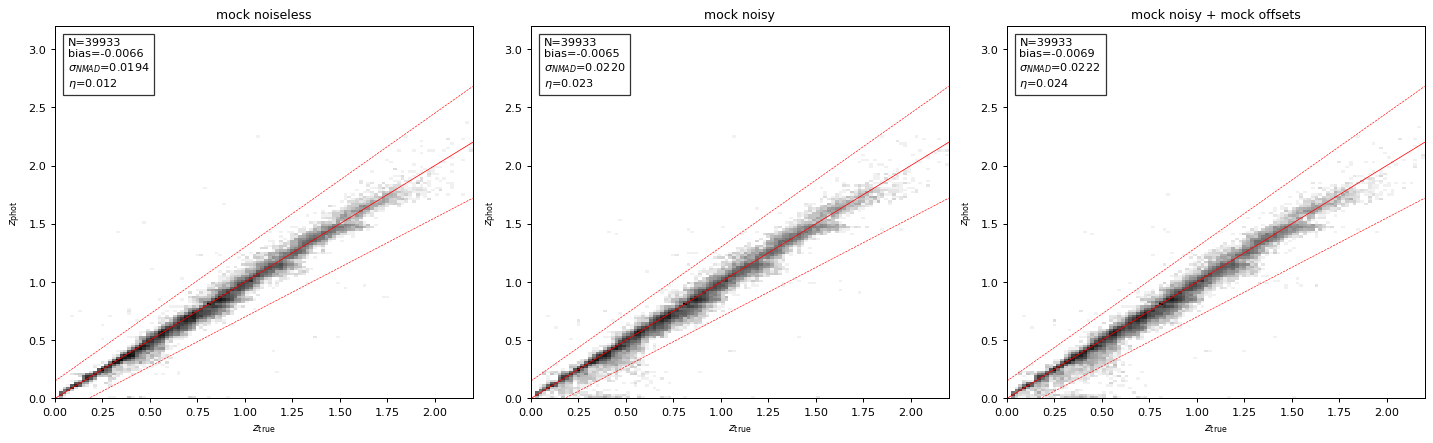

In [3]:
rows = {'noiseless (template-mismatch floor)': df_metrics(N0), 'noisy, no offsets (= sim_main)': df_metrics(Sd), 'noisy + mock AUTO_ADAPT offsets': df_metrics(A)}
display(pd.DataFrame(rows).T[['N', 'bias', 'nmad', 'eta', 'sig68', 'cov68']].round(4))
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
zz_panel(axs[0], N0.ztrue, N0.zp, title='mock noiseless'); zz_panel(axs[1], Sd.ztrue, Sd.zp, title='mock noisy'); zz_panel(axs[2], A.ztrue, A.zp, title='mock noisy + mock offsets')
plt.tight_layout(); plt.show()

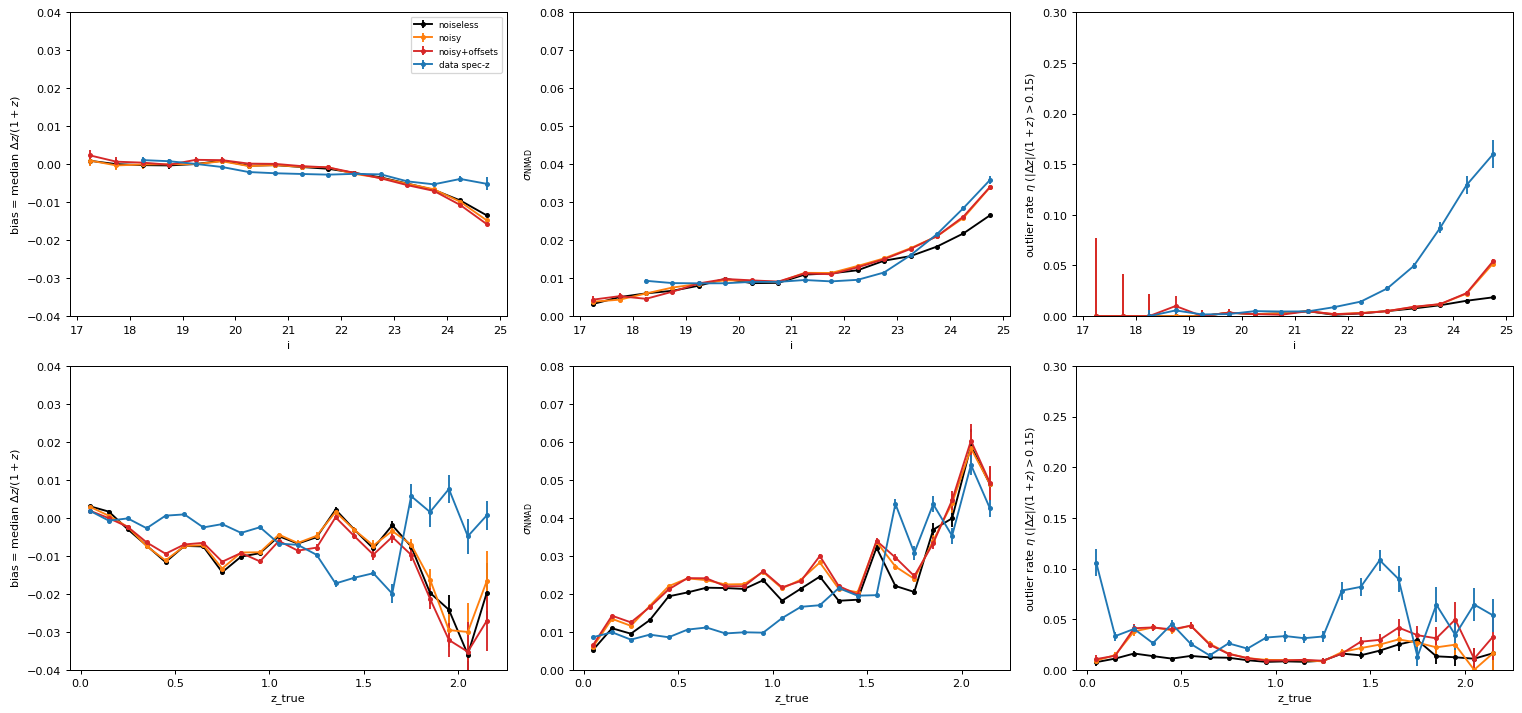

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(17, 8))
for r, (col, bins, lab) in enumerate([('i_mag', np.arange(17, 25.01, 0.5), 'i'), ('ztrue', np.arange(0, ZMAX + 0.01, 0.1), 'z_true')]):
    for name, df, c in [('noiseless', N0, 'k'), ('noisy', Sd, 'C1'), ('noisy+offsets', A, 'C3'), ('data spec-z', Ds, 'C0')]:
        t = binned(df, col, bins)
        for k, m in enumerate(['bias', 'nmad', 'eta']):
            axs[r, k].errorbar(t.x, t[m], yerr=t[f'{m}_err'], fmt='o-', ms=3, color=c, label=name)
            axs[r, k].set_ylim(*MLIM[m]); axs[r, k].set_xlabel(lab); axs[r, k].set_ylabel(MLAB[m])
axs[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Template-mismatch floor vs colour and redshift (noiseless mock)

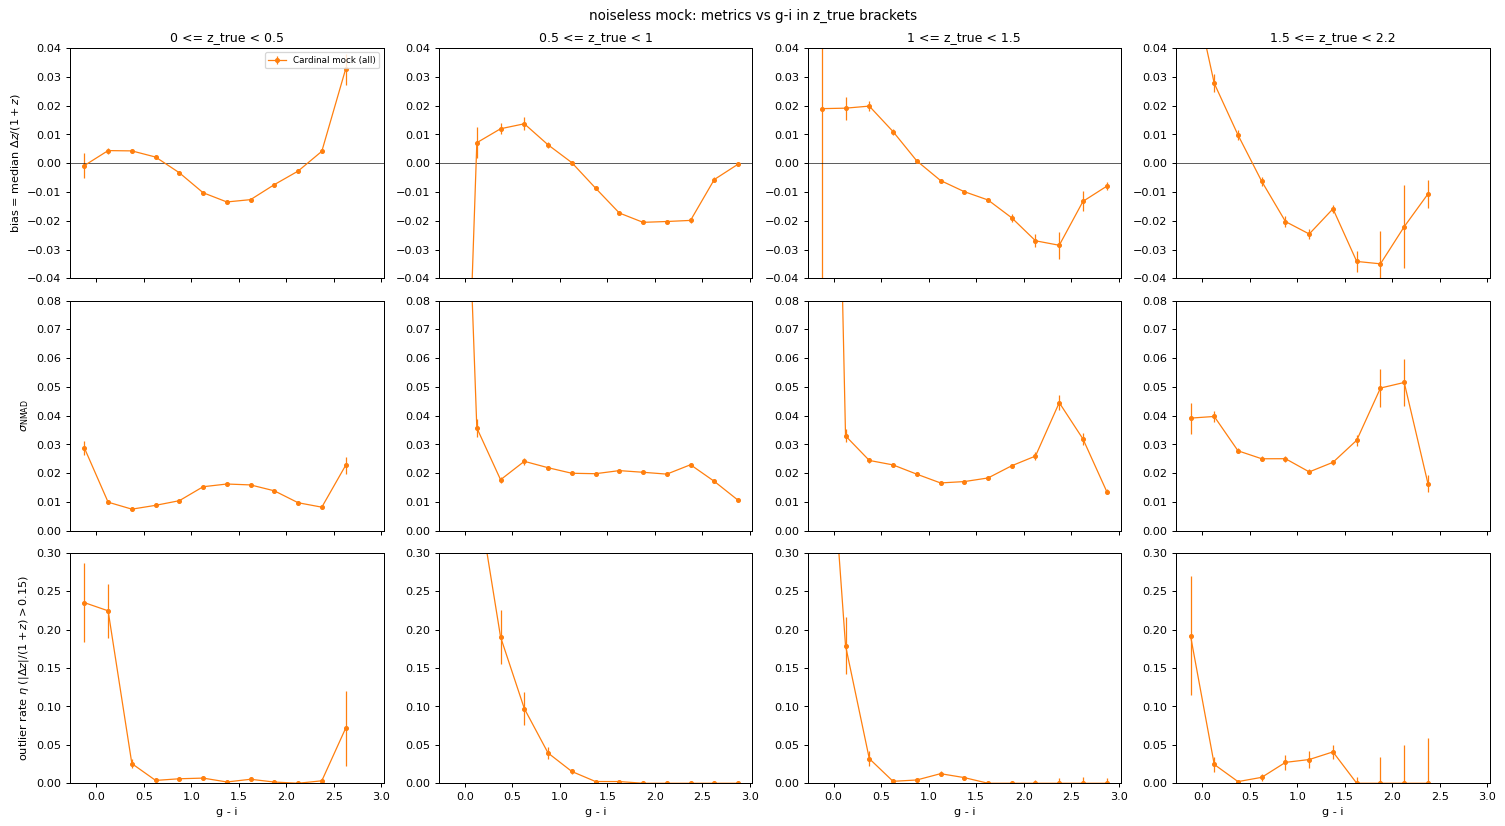

In [5]:
fig = curves_figure({'sim': (N0, None)}, 'g_i', np.arange(-0.25, 3.01, 0.25), [(0, 0.5), (0.5, 1), (1, 1.5), (1.5, ZMAX)], 'ztrue', 'z_true', 'g - i',
                    suptitle='noiseless mock: metrics vs g-i in z_true brackets'); plt.show()

## 2. Zero-point offsets: data vs mock

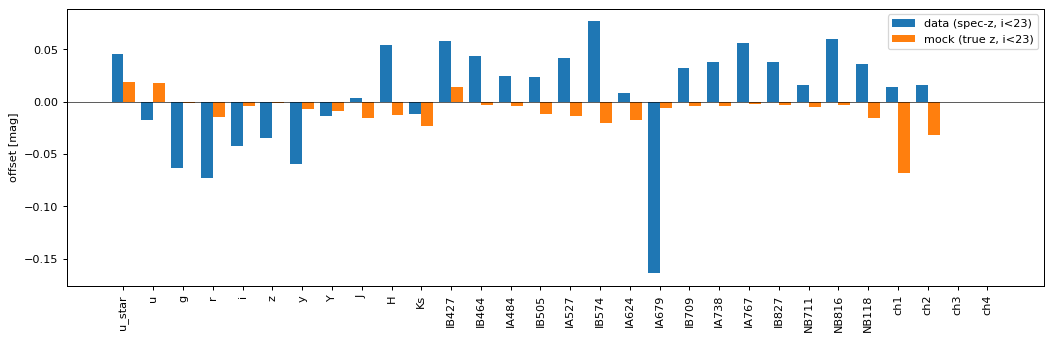

,u_star,u,g,r,i,z,y,Y,J,H,...,IA738,IA767,IB827,NB711,NB816,NB118,ch1,ch2,ch3,ch4
data,0.045,-0.018,-0.064,-0.073,-0.043,-0.034,-0.059,-0.014,0.004,0.055,...,0.038,0.056,0.038,0.016,0.060,0.036,0.014,0.016,0.0,0.0
mock,0.019,0.018,-0.001,-0.014,-0.004,-0.002,-0.007,-0.009,-0.015,-0.013,...,-0.004,-0.002,-0.003,-0.005,-0.003,-0.015,-0.068,-0.032,0.0,0.0


In [6]:
od = np.load(f'{RUNS}/data_run_offsets.npy'); os_ = np.load(f'{RUNS}/sim_adapt_offsets.npy')
x = np.arange(len(od))
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(x - 0.2, od, 0.4, label='data (spec-z, i<23)'); ax.bar(x + 0.2, os_, 0.4, label='mock (true z, i<23)')
ax.set_xticks(x); ax.set_xticklabels(list(BANDS), rotation=90); ax.axhline(0, c='k', lw=0.5); ax.set_ylabel('offset [mag]'); ax.legend()
plt.show()
pd.DataFrame({'data': od, 'mock': os_}, index=list(BANDS)).T.round(3)

## 3. Fit quality and best-fit templates

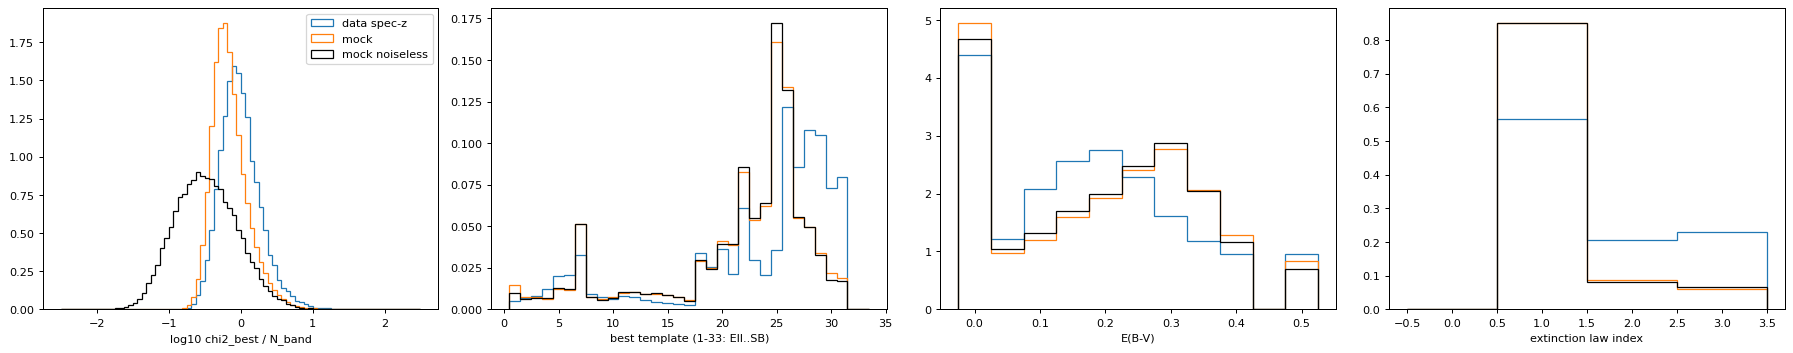

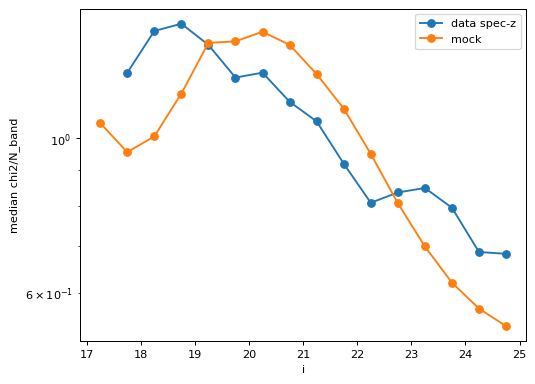

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(20, 4))
for name, df, c in [('data spec-z', Ds, 'C0'), ('mock', S, 'C1'), ('mock noiseless', N0, 'k')]:
    axs[0].hist(np.log10((df.CHI_BEST / df.NBAND_USED).clip(1e-3)), bins=80, range=(-2.5, 2.5), histtype='step', density=True, color=c, label=name)
    axs[1].hist(df.MOD_BEST, bins=np.arange(0.5, 34.5), histtype='step', density=True, color=c)
    axs[2].hist(df.EBV_BEST, bins=np.arange(-0.025, 0.55, 0.05), histtype='step', density=True, color=c)
    axs[3].hist(df.EXTLAW_BEST, bins=np.arange(-0.5, 4.5), histtype='step', density=True, color=c)
axs[0].set_xlabel('log10 chi2_best / N_band'); axs[0].legend(); axs[1].set_xlabel('best template (1-33: Ell..SB)'); axs[2].set_xlabel('E(B-V)'); axs[3].set_xlabel('extinction law index')
plt.tight_layout(); plt.show()
t = binned(S, 'i_mag', np.arange(17, 25.01, 0.5));
for name, df, c in [('data spec-z', Ds, 'C0'), ('mock', S, 'C1')]:
    g = df.assign(b=pd.cut(df.i_mag, np.arange(17, 25.01, 0.5))).groupby('b', observed=True)
    r = (df.CHI_BEST / df.NBAND_USED).groupby(pd.cut(df.i_mag, np.arange(17, 25.01, 0.5)), observed=True).median()
    plt.plot([i.mid for i in r.index], r.values, 'o-', color=c, label=name)
plt.yscale('log'); plt.xlabel('i'); plt.ylabel('median chi2/N_band'); plt.legend(); plt.show()

## 4. SOM comparison
SOM trained on the data broad-band colours (all clean i<25 objects in the data run); mock galaxies mapped onto the same cells. Per-cell metrics need ≥10 objects.

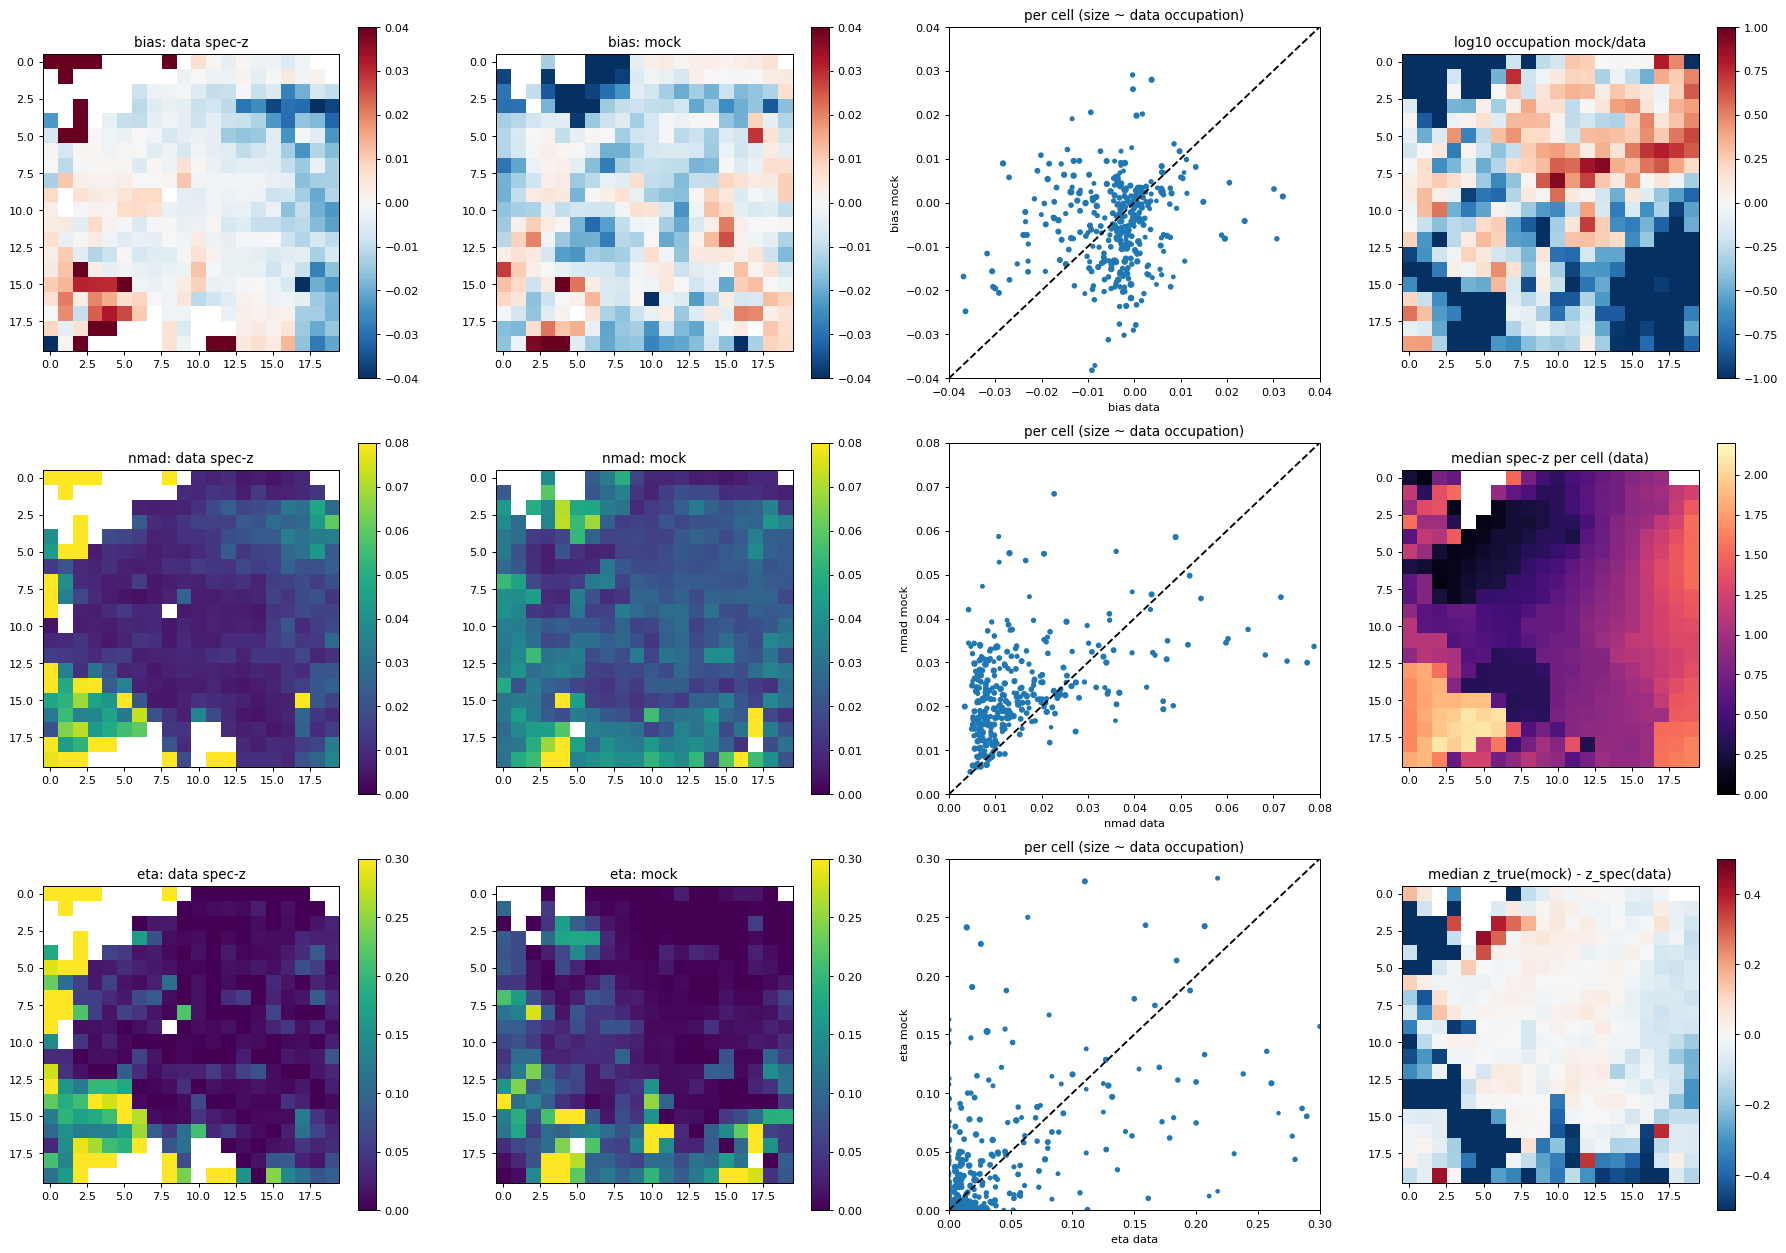

fraction of mock galaxies in cells with <0.01% data occupation: 0.0


In [8]:
from minisom import MiniSom
SB = ['u', 'g', 'r', 'i', 'z', 'y', 'Y', 'J', 'H', 'Ks']
def cols(df): return np.stack([df[f'm_{a}'] - df[f'm_{b}'] for a, b in zip(SB[:-1], SB[1:])], axis=1)
Dtr = D[(D.i_mag < 25)]
Xd = cols(Dtr); ok = np.isfinite(Xd).all(1); Xd = Xd[ok]; mu, sd = Xd.mean(0), Xd.std(0)
som = MiniSom(20, 20, Xd.shape[1], sigma=2.0, learning_rate=0.5, random_seed=3)
som.pca_weights_init((Xd - mu) / sd); som.train_random((Xd - mu) / sd, 200000)
W = som.get_weights().reshape(-1, Xd.shape[1])
def cell(df):
    X = (cols(df) - mu) / sd; X = np.nan_to_num(X)
    return np.concatenate([((X[i:i+50000, None, :] - W[None]) ** 2).sum(-1).argmin(1) for i in range(0, len(X), 50000)])
Ds['som'] = cell(Ds); S['som'] = cell(S); Dtr = Dtr.assign(som=cell(Dtr))
def per_cell(df):
    out = {}
    for c, g in df.groupby('som'):
        out[c] = df_metrics(g)
    return pd.DataFrame(out).T.reindex(range(400))
cd, cs = per_cell(Ds), per_cell(S)
occ_d = Dtr.som.value_counts(normalize=True).reindex(range(400)).fillna(0); occ_s = S.som.value_counts(normalize=True).reindex(range(400)).fillna(0)
fig, axs = plt.subplots(3, 4, figsize=(20, 14))
for r, m in enumerate(['bias', 'nmad', 'eta']):
    lo, hi = MLIM[m]
    for c, (t, name) in enumerate([(cd, 'data spec-z'), (cs, 'mock')]):
        v = t[m].where(t.N >= 10).values.astype(float).reshape(20, 20)
        im = axs[r, c].imshow(v, vmin=lo, vmax=hi, cmap='RdBu_r' if m == 'bias' else 'viridis'); plt.colorbar(im, ax=axs[r, c]); axs[r, c].set_title(f'{m}: {name}')
    ok = (cd.N >= 10) & (cs.N >= 10)
    axs[r, 2].scatter(cd[m][ok], cs[m][ok], s=5 + 3000 * occ_d[ok]); axs[r, 2].plot([lo, hi], [lo, hi], 'k--'); axs[r, 2].set_xlim(lo, hi); axs[r, 2].set_ylim(lo, hi)
    axs[r, 2].set_xlabel(f'{m} data'); axs[r, 2].set_ylabel(f'{m} mock'); axs[r, 2].set_title('per cell (size ~ data occupation)')
im = axs[0, 3].imshow(np.log10((occ_s + 1e-5) / (occ_d + 1e-5)).values.reshape(20, 20), cmap='RdBu_r', vmin=-1, vmax=1); plt.colorbar(im, ax=axs[0, 3]); axs[0, 3].set_title('log10 occupation mock/data')
zd = Ds.groupby('som').ztrue.median().reindex(range(400)).values.reshape(20, 20); zs = S.groupby('som').ztrue.median().reindex(range(400)).values.reshape(20, 20)
im = axs[1, 3].imshow(zd, cmap='magma', vmin=0, vmax=2.2); plt.colorbar(im, ax=axs[1, 3]); axs[1, 3].set_title('median spec-z per cell (data)')
im = axs[2, 3].imshow(zs - zd, cmap='RdBu_r', vmin=-0.5, vmax=0.5); plt.colorbar(im, ax=axs[2, 3]); axs[2, 3].set_title('median z_true(mock) - z_spec(data)')
plt.tight_layout(); plt.show()
print('fraction of mock galaxies in cells with <0.01% data occupation:', occ_s[occ_d < 1e-4].sum().round(3))

## Key findings (run of 2026-11-10)
1. **The mock's photo-z scatter is set by template mismatch, not by photometric noise.** On the same 40k galaxies, the noiseless run has σ_NMAD 0.019 (η 1.2%) vs 0.022 (η 2.3%) with noise. Up to i≈23 the noiseless and noisy curves coincide. Noise matters only at i>23: σ_NMAD 0.027→0.034 and η 2%→5% at 24<i<25.
2. **At fixed true redshift the mock is worse than the data** at 0.4<z<1.0 (σ_NMAD ≈0.02 vs ≈0.01). The COSMOS templates fit the mock's kcorrect SEDs less well than they fit real galaxies, even though χ²/N_band is lower in the mock. The per-SOM-cell comparison shows the same thing: mock σ_NMAD sits above the data wherever the data are very precise.
3. **Zero-point offsets.** Mock AUTO_ADAPT offsets are ≲0.02 mag in all optical/NIR bands, apart from IRAC ch1 (−0.07) and ch2 (−0.03); applying them changes nothing. The data offsets are larger (up to −0.16 in IA679, −0.07 in r) because they also absorb real calibration and template errors.
4. **Best-fit templates.** Mock galaxies pile onto a few COSMOS templates (7, 22, 25) and mostly the default extinction law. Real galaxies spread over more templates (especially the bluer 27–31) and use the bump extinction laws much more. This is the limited SED diversity of the SDSS-based library.
5. **SOM occupation.** The mock leaves parts of the data colour space under-populated (blue/occupation <0.1 cells), and in those cells its median z differs strongly from the data. Per-cell metrics are only meaningful where both are populated.